# <a href="https://girafe.ai/" target="_blank" rel="noopener noreferrer"><img src="https://raw.githubusercontent.com/girafe-ai/ml-course/7096a5df4cada5ee651be1e3215c2f7fb8a7e0bf/logo_margin.svg" alt="girafe-ai logo" width="150px" align="left"></a> [ml-basic course](https://github.com/girafe-ai/ml-course) <a class="tocSkip">

# Seminar 04: kNN indexes

In [ ]:
!pip install faiss-cpu

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.8/18.8 MB 114.2 MB/s  0:00:00


In [ ]:
import faiss
import h5py
import numpy as np

# Load embeddings

We will use pre-trained set of embeddings from Alternating Least Squares algorithm on Last.fm recommendation dataset.

See more info in [benchmark repo](https://github.com/erikbern/ann-benchmarks) and [dataset blogpost](https://www.benfrederickson.com/approximate-nearest-neighbours-for-recommender-systems/)

Code for downloading dataset should already work with several backend options.

If you experience troubles in downloading data automatically, you can do it manually using following links:
- [Google Drive](https://drive.google.com/file/d/1aRHohyQzW_w238jfXXEqfPOGCXn6WmH-/view)
- [Yandex Disk](https://disk.yandex.ru/d/DvnQBxK-RIvC6w)

In [ ]:
# Google Drive download
!pip install somepytools gdown
from somepytools.drives import download

data_path = download("1aRHohyQzW_w238jfXXEqfPOGCXn6WmH-")
data_path

Downloading...
From (original): https://drive.google.com/uc?id=1aRHohyQzW_w238jfXXEqfPOGCXn6WmH-
From (redirected): https://drive.google.com/uc?id=1aRHohyQzW_w238jfXXEqfPOGCXn6WmH-&confirm=t&uuid=0d80d91a-6ab0-4b1f-adb1-5549fb4a36d2
To: /content/lastfm-64-dot.hdf5
100%|██████████| 142M/142M [00:06<00:00, 22.6MB/s]


PosixPath('/content/lastfm-64-dot.hdf5')

In [ ]:
# Yandex Disk download
# !pip install somepytools yadisk
# from somepytools.drives import download

# data_path = download("https://disk.yandex.ru/d/DvnQBxK-RIvC6w")
# data_path

In [ ]:
with h5py.File(data_path) as file:
    item_factors = np.ascontiguousarray(file["train"], dtype=np.float32)
    user_factors = np.ascontiguousarray(file["test"], dtype=np.float32)
    true_neighbours = np.ascontiguousarray(file["neighbors"], dtype=np.float32)
    true_distances = np.ascontiguousarray(file["distances"], dtype=np.float32)

n_users, emb_dim = user_factors.shape

(
    item_factors.shape,
    user_factors.shape,
    true_neighbours.shape,
    item_factors.dtype,
    user_factors.dtype,
)

((292385, 65), (50000, 65), (50000, 100), dtype('float32'), dtype('float32'))

Most of the times we will use Inner Product (IP) indexes:

$<a, b> = \sum_i(a_i \cdot b_i)$

But for high dimensional case it's better to use cosine distance.
We need to normalize all embeddings and then use either L2 or Inner Product distance (they result in the same distances for normalised vectors):

In [ ]:
faiss.normalize_L2(item_factors)
faiss.normalize_L2(user_factors)

## EDA

Let's inspect pairwise L2 distances between item embeddings. The full pairwise matrix is too large to store, so we use a random subsample of item pairs for the histogram.

In [ ]:
import matplotlib.pyplot as plt


def pairwise_l2_distance_histogram(
    factors: np.ndarray,
    *,
    bins: int | np.ndarray = 100,
    subsampling_rate: float = 10**-5,
    sample_batch_size: int = 100_000,
    random_state: int = 42,
) -> tuple[np.ndarray, np.ndarray]:
    """Compute a histogram of L2 distances for sampled row pairs."""
    if not 0.0 < subsampling_rate < 1.0:
        raise ValueError("subsampling_rate must be in (0, 1).")

    factors = np.ascontiguousarray(factors, dtype=np.float32)

    if isinstance(bins, int):
        bin_edges = np.linspace(0.0, 2.0, bins + 1)
    else:
        bin_edges = np.asarray(bins, dtype=np.float64)

    hist = np.zeros(len(bin_edges) - 1, dtype=np.int64)
    squared_norms = np.einsum("ij,ij->i", factors, factors)
    n_items = factors.shape[0]
    n_pairs = n_items * (n_items - 1) // 2

    rng = np.random.default_rng(random_state)
    n_sampled_pairs = max(1, int(n_pairs * subsampling_rate))

    for start in range(0, n_sampled_pairs, sample_batch_size):
        size = min(sample_batch_size, n_sampled_pairs - start)
        left_idx = rng.integers(0, n_items, size=size)
        right_idx = rng.integers(0, n_items - 1, size=size)
        right_idx += right_idx >= left_idx

        squared_distances = (
            squared_norms[left_idx]
            + squared_norms[right_idx]
            - 2.0 * np.einsum("ij,ij->i", factors[left_idx], factors[right_idx])
        )
        distances = np.sqrt(np.maximum(squared_distances, 0.0))
        hist += np.histogram(distances, bins=bin_edges)[0]

    return hist, bin_edges

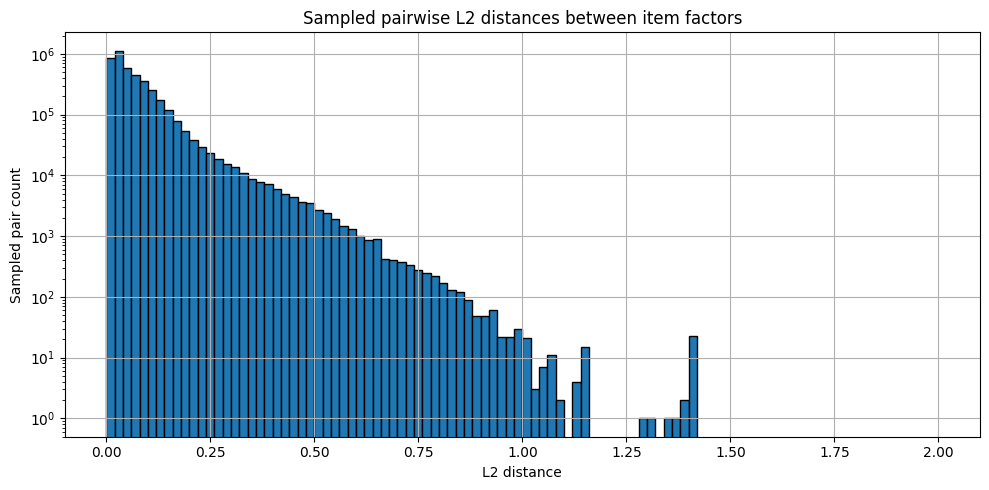

In [ ]:
l2_hist, l2_bin_edges = pairwise_l2_distance_histogram(
    item_factors, subsampling_rate=10**-4
)
l2_bin_centers = (l2_bin_edges[:-1] + l2_bin_edges[1:]) / 2.0

plt.figure(figsize=(10, 5))
plt.bar(
    l2_bin_centers,
    l2_hist,
    width=np.diff(l2_bin_edges),
    align="center",
    edgecolor="black",
)
plt.xlabel("L2 distance")
plt.ylabel("Sampled pair count")
plt.yscale("log")
plt.title("Sampled pairwise L2 distances between item factors")
plt.grid()
plt.tight_layout()
plt.show()

# Naive algorithm

To have a baseline we first consider different implementations of nainve algorithm.

We will evaluate index algorithms against random queries, so let's write a sample funtion:

In [ ]:
rng = np.random.default_rng(42)


def sample_query_batch(
    user_factors: np.ndarray,
    n_queries: int,
) -> np.ndarray:
    """Return a contiguous float32 batch of ``n_queries`` distinct user rows."""
    n_users = user_factors.shape[0]
    batch_idx = rng.choice(n_users, size=n_queries, replace=False)
    return np.ascontiguousarray(user_factors[batch_idx], dtype=np.float32)

In [ ]:
n_neighbours = 50  # Choose 50 nearest neighbours
n_queries = 100  # 100 users is real example of request batch

queries_embeddings = sample_query_batch(user_factors, n_queries)

## Numpy implementation

First we implement naive method using `numpy` to find nearest neighbours.

In [ ]:
%%timeit
# too long because we sort full array
product = queries_embeddings.dot(item_factors.T)
indexes_exact = np.argsort(product, axis=1)[:, : -n_neighbours - 1 : -1]

1.63 s ± 268 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)


Actually we don't need to sort the whole array but only top `n_neighbours` of it.

What are algorithmic complexities of full sorting and [partial sorting](https://en.wikipedia.org/wiki/Partial_sorting)?

In [ ]:
def numpy_knn(
    item_factors, queries_embeddings, n_neighbours: int
) -> tuple[np.ndarray, np.ndarray]:
    product = queries_embeddings.dot(item_factors.T)

    # partial sort of the big array
    top_idx = np.argpartition(product, -n_neighbours, axis=1)[:, -n_neighbours:]
    top_scores = np.take_along_axis(product, top_idx, axis=1)

    # exact sorting of closest neighbours
    order = np.argsort(top_scores, axis=1)[:, ::-1]
    distances_exact = np.take_along_axis(top_scores, order, axis=1)
    indexes_exact = np.take_along_axis(top_idx, order, axis=1)

    return distances_exact, indexes_exact


distances_exact, indexes_exact = numpy_knn(
    item_factors, queries_embeddings, n_neighbours
)

In Jupyter notebooks [`timeit` magic command](https://ipython.readthedocs.io/en/stable/interactive/magics.html#magic-timeit) is a benchmark command, so it doesn't assign variables by default

In [ ]:
%%timeit
numpy_knn(item_factors, queries_embeddings, n_neighbours)

286 ms ± 5.73 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)


## Faiss implementation

For now we use CPU version because lots of kNN indexing is happening on CPU.

[Faiss wiki](https://github.com/facebookresearch/faiss/wiki) with algorithms details, especially useful page is [Faiss indexes page](https://github.com/facebookresearch/faiss/wiki/Faiss-indexes).\
[Faiss docs](https://faiss.ai/) with API details.\
Unfortunately Faiss documentation is C++ first and not best in class, Python API is a product of [Simplified Wrapper and Interface Generator (SWIG)](https://en.wikipedia.org/wiki/SWIG), but you may use chat bots to answer particular questions.

Note: Google Colab notebook environments carry very low CPU resource, so even such simple indexing may take significant amount of time (10. mins and more for single HNSW index). It is recommended to run this notebook on fully fledged CPU hardware e.g. local notebook environment rather than Colab.

`IndexFlatIP` is a naive algorithm implemented in C++, so it should be faster than Python implementation, we will check it. This simple algorithm has no moving parts, so no hyperparameter setup is needed.

Note: in Jupyter [`time` magic command](https://ipython.readthedocs.io/en/stable/interactive/magics.html#magic-time) is responsible for printing time of cell evaluation

For now let's use it to get familiar with API:

In [ ]:
%%time
# Create index Exact Search for Inner Product
index_flat = faiss.IndexFlatIP(emb_dim)

# Add document embeddings to index
index_flat.add(item_factors)
print(f"Objects in an index: {index_flat.ntotal}")

Objects in an index: 292385
CPU times: user 27.2 ms, sys: 33.9 ms, total: 61.2 ms
Wall time: 61.3 ms


In [ ]:
distances_flat, indexes_flat = index_flat.search(queries_embeddings, n_neighbours)

In [ ]:
%%timeit
index_flat.search(queries_embeddings, n_neighbours)

574 ms ± 33.5 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)


Faiss API returns distances and indexes of items in original array (passed to `.add`), let's inspect it:

In [ ]:
distances_flat.shape, indexes_flat.shape

((100, 50), (100, 50))

In [ ]:
distances_flat[:5, :5]

array([[0.11502385, 0.10897875, 0.10694878, 0.10542169, 0.10326232],
       [0.13241589, 0.12525797, 0.12126207, 0.11852355, 0.11746353],
       [0.1457313 , 0.14372268, 0.13948052, 0.13824624, 0.13671431],
       [0.09159282, 0.08832796, 0.08651282, 0.08636884, 0.08594237],
       [0.11342128, 0.11224783, 0.11166064, 0.11107091, 0.10884656]],
      dtype=float32)

In [ ]:
indexes_flat[:5, :5]

array([[106840, 168858, 277559, 161982, 138284],
       [114067, 186369, 250342,  86649, 220575],
       [182797, 166343, 192140, 136898, 191146],
       [237648, 255326, 116817,  55917, 197840],
       [274818,  73506, 233630, 183277, 171789]])

## Proper quality comparison

Let's write a function to compare two sets of nearest neighbours with different quality metrics.

We will need to adress distances difference as well as neighbours intersection.

In [ ]:
# TODO provide average distance between points for reference
from typing import Any


def recall(
    left_dists: np.ndarray,
    left_indexes: np.ndarray,
    right_dists: np.ndarray,
    right_indexes: np.ndarray,
) -> np.ndarray:
    # TODO add @k
    return np.fromiter(
        (
            len(set(left_row.tolist()) & set(right_row.tolist()))
            for left_row, right_row in zip(left_indexes, right_indexes)
        ),
        dtype=np.int32,
        count=len(left_indexes),
    )


def compute_metrics(
    left_dists: np.ndarray,
    left_indexes: np.ndarray,
    right_dists: np.ndarray,
    right_indexes: np.ndarray,
    *,
    atol: float = 1e-4,
    rtol: float = 1e-4,
) -> dict[str, Any]:
    metrics = {}
    n_queries, n_neighbours = left_indexes.shape

    metrics["distances_allclose"] = np.allclose(
        left_dists, right_dists, atol=atol, rtol=rtol
    )

    metrics["abs_diff"] = np.abs(left_dists - right_dists)
    metrics["distance_mean_abs_diff"] = metrics["abs_diff"].mean()
    metrics["distance_max_abs_diff"] = metrics["abs_diff"].max()

    metrics["position_match_ratio"] = np.mean(left_indexes == right_indexes)

    overlap_counts = recall(left_dists, left_indexes, right_dists, right_indexes)
    metrics["mean_set_overlap_ratio"] = overlap_counts.mean() / n_neighbours
    metrics["min_set_overlap_ratio"] = overlap_counts.min() / n_neighbours

    return metrics


def compare_nn_result(
    left_dists: np.ndarray,
    left_indexes: np.ndarray,
    right_dists: np.ndarray,
    right_indexes: np.ndarray,
    *,
    atol: float = 1e-4,
    rtol: float = 1e-4,
) -> dict[str, float | bool]:
    """Print and return distance/index similarity metrics for two kNN results.

    Args:
        left_dists: Distances or scores from method A, shape (n_queries, k).
        left_indexes: Neighbor indexes from method A, shape (n_queries, k).
        right_dists: Distances or scores from method B, shape (n_queries, k).
        right_indexes: Neighbor indexes from method B, shape (n_queries, k).
        atol: Absolute tolerance for distance comparison.
        rtol: Relative tolerance for distance comparison.

    Returns:
        Dictionary with key similarity metrics.
    """
    metrics = compute_metrics(
        left_dists, left_indexes, right_dists, right_indexes, atol=atol, rtol=rtol
    )

    print("kNN comparison report")
    print(f"- n_queries={n_queries}, k={n_neighbours}")
    print("- distances:")
    print(f"    allclose(atol={atol}, rtol={rtol}): {metrics['distances_allclose']}")
    print(f"    mean_abs_diff: {metrics['distance_mean_abs_diff']:.6e}")
    print(f"    max_abs_diff: {metrics['distance_max_abs_diff']:.6e}")
    print("- indexes:")
    print(f"    position_match_ratio: {metrics['position_match_ratio']:.6f}")
    print(f"    mean_set_overlap_ratio: {metrics['mean_set_overlap_ratio']:.6f}")
    print(f"    min_set_overlap_ratio: {metrics['min_set_overlap_ratio']:.6f}")

In [ ]:
compare_nn_result(distances_exact, indexes_exact, distances_flat, indexes_flat)

kNN comparison report
- n_queries=100, k=50
- distances:
    allclose(atol=0.0001, rtol=0.0001): True
    mean_abs_diff: 8.853525e-09
    max_abs_diff: 5.215406e-08
- indexes:
    position_match_ratio: 1.000000
    mean_set_overlap_ratio: 1.000000
    min_set_overlap_ratio: 1.000000


## Benchmark time correctly

Above check is not fair because queires are the same each time, so we need to make them different, let's implement it in Python:

In [ ]:
from time import perf_counter
from collections.abc import Callable


def benchmark_index_search(
    index_fn: Callable,
    user_factors: np.ndarray,
    n_neighbours: int,
    n_queries: int,
    warmup: int = 5,
    repeats: int = 25,
    # metrics_fn: Callable | None = None,
) -> np.ndarray:
    """Return elapsed search times in milliseconds for random query batches."""
    for _ in range(warmup):
        index_fn(sample_query_batch(user_factors, n_queries), n_neighbours)

    elapsed_times = np.empty(repeats, dtype=np.float64)
    for i in range(repeats):
        queries = sample_query_batch(user_factors, n_queries)

        t_start = perf_counter()
        distances, indexes = index_fn(queries, n_neighbours)
        elapsed_times[i] = perf_counter() - t_start

        # metrics_fn()

    return elapsed_times * 1000.0


def benchmark_results(
    index: faiss.Index,
    user_factors: np.ndarray,
    n_neighbours: int,
    n_queries: int,
    *,
    warmup: int = 5,
    repeats: int = 25,
) -> None:
    """Run index.search on random user batches and print timing.

    Warmup avoids measuring one-off allocator / cache effects.

    More parameters to benchmark:
        - recall@1, recall@10, recall@100
        - memory
        - sensitivity to query batch size
    """
    ms = benchmark_index_search(
        index,
        user_factors,
        n_neighbours,
        n_queries,
        warmup,
        repeats,
    )
    p50_ms, p95_ms, p99_ms = np.percentile(ms, [50.0, 95.0, 99.0])

    print(f"Index type: {type(index).__name__} performance:")
    print(
        f"  n_queries={n_queries}, n_neighbours={n_neighbours}, user_factors shape={user_factors.shape}, warmup={warmup}, timed repeats={repeats}"
    )
    print("  time per call:")
    print(f"    mean={ms.mean():.3f} ms, std={ms.std(ddof=1):.3f} ms")
    print(f"    min={ms.min():.3f} ms, max={ms.max():.3f} ms")
    print("  quantiles (ms):")
    print(f"    p50={p50_ms:.3f} ms, p95={p95_ms:.3f} ms, p99={p99_ms:.3f} ms")
    print(
        f"  throughput: {n_queries / (ms.mean() / 1000.0):.1f} queries/s (mean batch)"
    )

In [ ]:
benchmark_results(index_flat.search, user_factors, n_neighbours, n_queries)

Index type: method performance:
  n_queries=100, n_neighbours=50, user_factors shape=(50000, 65), warmup=5, timed repeats=25
  time per call:
    mean=590.845 ms, std=140.334 ms
    min=441.868 ms, max=1007.755 ms
  quantiles (ms):
    p50=569.209 ms, p95=869.737 ms, p99=976.943 ms
  throughput: 169.2 queries/s (mean batch)


# k-d tree with scikit-learn

By default `sklearn` uses [k-d tree algorithm](https://en.wikipedia.org/wiki/K-d_tree) for its [neighbours models](https://sklearn.org/stable/api/sklearn.neighbors.html).

Let's inspect that approach and compare it with others:

In [ ]:
from sklearn.neighbors import KDTree

KDTree.valid_metrics

['euclidean',
 'l2',
 'minkowski',
 'p',
 'manhattan',
 'cityblock',
 'l1',
 'chebyshev',
 'infinity']

In [ ]:
%time
tree = KDTree(item_factors)

CPU times: user 3 µs, sys: 0 ns, total: 3 µs
Wall time: 6.2 µs


In [ ]:
distances_kdtree, indexes_kdtree = tree.query(queries_embeddings, n_neighbours)

In [ ]:
compare_nn_result(distances_exact, indexes_exact, distances_flat, indexes_flat)

kNN comparison report
- n_queries=100, k=50
- distances:
    allclose(atol=0.0001, rtol=0.0001): True
    mean_abs_diff: 8.853525e-09
    max_abs_diff: 5.215406e-08
- indexes:
    position_match_ratio: 1.000000
    mean_set_overlap_ratio: 1.000000
    min_set_overlap_ratio: 1.000000


In [ ]:
benchmark_results(tree.query, user_factors, n_neighbours, n_queries)

Index type: method performance:
  n_queries=100, n_neighbours=50, user_factors shape=(50000, 65), warmup=5, timed repeats=25
  time per call:
    mean=1959.579 ms, std=205.823 ms
    min=1784.281 ms, max=2472.439 ms
  quantiles (ms):
    p50=1859.537 ms, p95=2386.937 ms, p99=2455.613 ms
  throughput: 51.0 queries/s (mean batch)


# HNSW with Faiss

<img src="https://drive.google.com/uc?export=view&id=1CZlsisey6UWP5rccRE2QaLuInIUkCM2J" width="500">

Hierarchical navigable small world (HNSW) - advanced graph-based approximate nearest neighbor algorithm.

We will use it to the same problem and compare it with previous solutions.\
But HNSW is more complex structure, so it needs proper configuration of hyperparameters.


Cricial hyperparameters of [Faiss implementaion](https://faiss.ai/cpp_api/struct/structfaiss_1_1IndexHNSWFlat.html) are:

**`M` — graph connectivity.**  
Controls how many neighbors each vector keeps in the HNSW graph. Larger `M` usually gives better recall because the graph has more alternative search paths, but increases memory usage, index construction time, and often query time. In `faiss.IndexHNSWFlat(d, M, metric)`, the second argument is `M`, not the number of returned nearest neighbors.

**`efConstruction` — construction-time search depth.**  
Controls how carefully Faiss searches for good graph neighbors while adding vectors to the index. Larger `efConstruction` usually builds a better graph and improves final recall, but makes index construction slower. It is paid during `index.add(...)`, not during ordinary search.

**`efSearch` — query-time search depth.**  
Controls how many candidate nodes HNSW explores during search. Larger `efSearch` usually improves recall, but increases query latency. This is the main knob to tune the speed–quality tradeoff after the index has already been built.

In [ ]:
%%time

M = 32 # 32
ef_construction = 100 # 100
ef_search = 64 # 64

index_hnsw = faiss.IndexHNSWFlat(emb_dim, M, faiss.METRIC_INNER_PRODUCT)
index_hnsw.hnsw.efConstruction = ef_construction
index_hnsw.hnsw.efSearch = ef_search

index_hnsw.add(item_factors)

CPU times: user 51.9 s, sys: 141 ms, total: 52 s
Wall time: 29.8 s


In [ ]:
distances_hnsw, indexes_hnsw = index_hnsw.search(queries_embeddings, n_neighbours)

In [ ]:
compare_nn_result(distances_exact, indexes_exact, distances_hnsw, indexes_hnsw)

kNN comparison report
- n_queries=100, k=50
- distances:
    allclose(atol=0.0001, rtol=0.0001): False
    mean_abs_diff: 5.876927e-04
    max_abs_diff: 3.376263e-02
- indexes:
    position_match_ratio: 0.561600
    mean_set_overlap_ratio: 0.928200
    min_set_overlap_ratio: 0.160000


In [ ]:
benchmark_results(index_hnsw.search, user_factors, n_neighbours, n_queries)

Index type: method performance:
  n_queries=100, n_neighbours=50, user_factors shape=(50000, 65), warmup=5, timed repeats=25
  time per call:
    mean=6.114 ms, std=0.632 ms
    min=5.656 ms, max=8.916 ms
  quantiles (ms):
    p50=5.999 ms, p95=6.710 ms, p99=8.404 ms
  throughput: 16356.9 queries/s (mean batch)


Results are not brilliant. This is because we have taken default hyperparameter values.

## Optuna for hyperparameters tuning

Let's use `optuna` to find optimal configuration of HNSW for our dataset.

It has [multiobjective optimization capabilities](https://optuna.readthedocs.io/en/stable/tutorial/20_recipes/002_multi_objective.html), so we need to put time and quality as targets:

In [ ]:
!pip install optuna

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 442.4/442.4 kB 15.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 20.1 MB/s eta 0:00:00


In [ ]:
import optuna

Algorithm is not tuned for the dataset, so results are not the best. But you can find optimal parameters for 99% or even 99.9%.

Faiss also has different encoding strategies which extend tradeoff between resources used and results quality:

| Index             | Meaning                   | Tradeoff                           |
| ----------------- | ------------------------- | ---------------------------------- |
| `IndexHNSWFlat`   | full vectors              | best accuracy, high RAM            |
| `IndexHNSWSQ`     | scalar-quantized vectors  | lower RAM, some accuracy loss      |
| `IndexHNSWPQ`     | product-quantized vectors | much lower RAM, more accuracy loss |
| `IndexHNSW2Level` | two-level encoding        | compression-oriented variant       |

It also exposes incremental addition of vectors into grapth structure.